# Efficient Data Loading with Dask in xsnow

**Tutorial: Lazy Loading, Task Graphs, and When to Compute**

This tutorial covers:
- Understanding lazy evaluation with Dask
- Loading and exploring gridded SNOWPACK data efficiently
- Best practices for avoiding complex task graphs
- Practical example: Mapping snow height across a grid

---

## 1. What is Lazy Loading?

**Lazy loading** means data operations are *defined* but not *executed* until explicitly requested. Think of it as building a recipe instead of cooking the meal.

### Why Use Lazy Loading?

✅ **Memory efficiency**: Work with datasets larger than RAM  
✅ **Performance**: Only compute what you need  
✅ **Optimization**: Dask can optimize your entire workflow before executing  

### How xsnow Uses Dask

When xsnow reads SNOWPACK data with `read()`, it creates **Dask arrays** by default:
- Metadata is loaded immediately (dimensions, coordinates, attributes)
- Array data stays on disk until needed
- Operations build a "task graph" that executes when you call `.compute()`

In [1]:
# Import the necessary libraries
import xsnow
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

In [2]:

# Use testing data path
# If you have your own data, change this path!
data_path = Path("snowpack_archive.nc")
if data_path.exists():
    ds = xsnow.read(data_path)
else:
    DATA_PATH = Path("/path/to/your/data")  # Change this!
if not DATA_PATH.exists():
    DATA_PATH = Path(xsnow.sample_data.snp_gridded_dir())
    print(f"Using sample data from {DATA_PATH}")
    
file_count = len(list(DATA_PATH.rglob("*.pro")))
print(f"Number of files to load: {file_count}")
# Load sample gridded dataset and save it as a NetCDF file for future use
ds = xsnow.read(DATA_PATH, recursive=True)

print("Dataset loaded!")
print(f"\nDataset dimensions: {dict(ds.data.sizes)}")

# Check dataset size
n_files = ds.data.sizes.get('location', 0) * ds.data.sizes.get('slope', 0)
if n_files > 50:
    print(f"\nLarge dataset detected ({n_files} location-slope combinations)")
    print("Some examples will use subsets to avoid kernel crashes.")
    print("This is normal and demonstrates best practices for large datasets!")

[i] xsnow.xsnow_io: Using lazy loading with Dask


Using sample data from /home/ron/.cache/xsnow-snp-gridded
Number of files to load: 25


[i] xsnow.xsnow_io: Creating lazy datasets backed by dask arrays...
[i] xsnow.xsnow_io: Data will NOT be computed until explicitly requested by user
[i] xsnow.xsnow_io: Using parallel lazy creation with 15 workers...
[i] xsnow.xsnow_io: Created 25 lazy datasets (data NOT yet loaded into memory)


Dataset loaded!

Dataset dimensions: {'location': 5, 'time': 418, 'slope': 5, 'realization': 1, 'layer': 33}


## 2. Exploring Data Without Computing

You can inspect metadata, dimensions, and coordinates without loading any actual data:

In [4]:
# This is FAST - no data loaded!
print("Available variables:")
print(list(ds.data.data_vars)[:20])  # Just show first 20
print(f"\nTime range: {ds.data.time.values[0]} to {ds.data.time.values[-1]}")
print(f"Number of locations: {len(ds.data.location)}")
print(f"Number of slopes: {len(ds.data.slope)}")
print(f"Number of layers: {len(ds.data.layer)}")

Available variables:
['accumulated_temperature_gradient', 'air_content', 'bond_size', 'coord_number', 'dendricity', 'density', 'element_ID', 'grain_size', 'grain_type', 'gs_difference', 'hand_hardness', 'hardness_difference', 'height', 'ice_content', 'lwc', 'opt_equ_grain_size', 'profile_status', 'shear_strength', 'sk38', 'sn38']

Time range: 2024-10-17T12:00:00.000000000 to 2025-06-01T12:00:00.000000000
Number of locations: 69
Number of slopes: 4
Number of layers: 119


In [5]:
# Check if data is lazy-loaded (Dask array)
print("Is 'temperature' lazy-loaded?")
print(type(ds.data['temperature'].data))
print(f"\nArray shape: {ds.data['temperature'].shape}")
print(f"Chunk sizes: {ds.data['temperature'].chunks}")

Is 'temperature' lazy-loaded?
<class 'dask.array.core.Array'>

Array shape: (69, 909, 4, 1, 119)
Chunk sizes: ((1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1), (100, 100, 100, 100, 100, 100, 100, 100, 100, 9), (1, 1, 1, 1), (1,), (119,))


## 3. Operations Stay Lazy Until Compute

Most xarray operations return lazy arrays - no computation happens yet!

In [6]:
# These operations are INSTANT - just building the task graph
temp_celsius = ds.data['temperature'] - 273.15
mean_temp = temp_celsius.mean(dim='layer')  # Average across vertical layers
max_temp = temp_celsius.max(dim=['time', 'layer'])

print("Operations defined, but NO computation yet!")
print(f"Type: {type(mean_temp.data)}")
print(f"\nTask graph size: {len(mean_temp.__dask_graph__())} tasks")

Operations defined, but NO computation yet!
Type: <class 'dask.array.core.Array'>

Task graph size: 17378 tasks


## 4. Selection and Subsetting: Still Lazy!

Selecting subsets of data also stays lazy:

In [7]:
# Select a single location and time range - still lazy!
# Use the first location from whatever dataset is loaded
first_location = ds.data.location.values[0]
print(f"Selecting location: {first_location}\n")

single_location = ds.sel(location=[first_location])

# Select a time range (adapt to your data's time range)
time_values = ds.data.time.values
if len(time_values) > 100:
    # Select a 5-day window from the dataset
    start_time = time_values[50]
    end_time = time_values[min(100, len(time_values)-1)]
    recent_data = single_location.sel(time=slice(start_time, end_time))
else:
    recent_data = single_location

print("Selection made, but data still on disk!")
print(f"Selected shape: {recent_data.data['temperature'].shape}")
print(f"Type: {type(recent_data.data['temperature'].data)}")

Selecting location: Z038_075337

Selection made, but data still on disk!
Selected shape: (1, 51, 4, 1, 119)
Type: <class 'dask.array.core.Array'>


## 5. When to Call `.compute()`

### ✅ GOOD: Compute after selecting/aggregating

Reduce data size BEFORE computing:

In [8]:
# GOOD PATTERN: Select → Aggregate → Compute
first_loc = ds.data.location.values[0]
one_location = ds.sel(location=[first_loc])
mean_profile = one_location.data['temperature'].mean(dim=['time', 'slope'])

# Now compute the much smaller result
result = mean_profile.compute()
print(f"Computed result shape: {result.shape}")
print(f"Type: {type(result.data)}")

Computed result shape: (1, 1, 119)
Type: <class 'numpy.ndarray'>


### ❌ BAD: Computing too early

In [9]:
# BAD PATTERN: Don't do this!
# This loads ALL data into memory before selecting
# all_data = ds.data.compute()  # ← DON'T DO THIS!
# subset = all_data.sel(location=location_name)

print("⚠️  Never compute the entire dataset before selecting!")
print("Always select/aggregate BEFORE computing.")

⚠️  Never compute the entire dataset before selecting!
Always select/aggregate BEFORE computing.


## 6. Understanding Task Graphs: What's Really Happening

### Myth: "Chaining operations creates huge task graphs"
### Reality: "Dask is smarter than that!"

Let's see what actually happens when we chain operations...

In [10]:
if 'temperature' in ds.data:
    # Check the base task graph size
    base_temp = ds.data['temperature']
    print(f"Base dataset: {base_temp.shape}")
    print(f"Base task graph: {len(base_temp.__dask_graph__()):,} tasks")
    print("(These tasks come from reading your files)\n")

Base dataset: (69, 909, 4, 1, 119)
Base task graph: 31,626 tasks
(These tasks come from reading your files)



### Experiment: Chain 5 Operations

In [11]:
if 'temperature' in ds.data:
    # Use a small subset so we can see the pattern clearly
    demo_data = ds.data['temperature'].isel(location=0, slope=0, time=slice(0, 100))
    
    print("Building operation chain...\n")
    print(f"Starting:          {len(demo_data.__dask_graph__()):,} tasks")
    
    step1 = demo_data - 273.15
    print(f"Step 1 (subtract): {len(step1.__dask_graph__()):,} tasks (+{len(step1.__dask_graph__()) - len(demo_data.__dask_graph__())})")
    
    step2 = step1.where(step1 > -10)
    print(f"Step 2 (where):    {len(step2.__dask_graph__()):,} tasks (+{len(step2.__dask_graph__()) - len(step1.__dask_graph__())})")
    
    step3 = step2.rolling(layer=3).mean()
    print(f"Step 3 (rolling):  {len(step3.__dask_graph__()):,} tasks (+{len(step3.__dask_graph__()) - len(step2.__dask_graph__())})")
    
    step4 = step3.fillna(0)
    print(f"Step 4 (fillna):   {len(step4.__dask_graph__()):,} tasks (+{len(step4.__dask_graph__()) - len(step3.__dask_graph__())})")
    
    step5 = step4 * 1.8 + 32
    print(f"Step 5 (convert):  {len(step5.__dask_graph__()):,} tasks (+{len(step5.__dask_graph__()) - len(step4.__dask_graph__())})")
    
    total_growth = len(step5.__dask_graph__()) - len(demo_data.__dask_graph__())
    print(f"\n📊 Total growth: +{total_growth} tasks for 5 operations")
    print("\n✅ Barely any growth! This is GOOD - it's called **task graph fusion**")

Building operation chain...

Starting:          31,628 tasks
Step 1 (subtract): 31,629 tasks (+1)
Step 2 (where):    31,631 tasks (+2)
Step 3 (rolling):  31,635 tasks (+4)
Step 4 (fillna):   31,638 tasks (+3)
Step 5 (convert):  31,640 tasks (+2)

📊 Total growth: +12 tasks for 5 operations

✅ Barely any growth! This is GOOD - it's called **task graph fusion**


### What Just Happened? Task Graph Fusion!

**You probably expected**: Each operation adds thousands of tasks  
**What actually happened**: 5 operations added only ~10-20 tasks

**Why?** Dask **fuses simple operations together**:

```python
# What you wrote:
temp - 273.15  →  .where(...)  →  * 1.8  →  + 32

# What Dask actually does:
def fused_operation(chunk):
    result = chunk - 273.15
    result = result.where(result > -10)
    result = result * 1.8 + 32
    return result
# Single task per chunk!
```

Dask combines **element-wise operations** into a single function call. This is automatic and awesome!

### So What's The REAL Problem?

The problem isn't chaining operations - it's **the BASE SIZE of your dataset**:

In [12]:
if 'temperature' in ds.data:
    base_graph_size = len(ds.data['temperature'].__dask_graph__())
    n_locations = ds.data.sizes['location']
    n_slopes = ds.data.sizes.get('slope', 1)
    n_times = ds.data.sizes['time']
    
    print(f"Your dataset dimensions:")
    print(f"  {n_locations} locations × {n_slopes} slopes × {n_times} timesteps")
    print(f"\nBase task graph: {base_graph_size:,} tasks\n")
    
    print("Where do these tasks come from?")
    print(f"  • Your dataset has {n_locations * n_slopes} location-slope combos")
    print(f"  • Each is split into time chunks")
    print(f"  • Each chunk = one task to read from disk")
    print(f"  • Result: {base_graph_size:,} tasks BEFORE any operations!\n")
    
    print("💡 The scheduler overhead comes from:")
    print("   1. Scheduling 100,000+ file-reading tasks")
    print("   2. Tracking dependencies between chunks")
    print("   3. Managing memory across all chunks")
    print("\n⚠️  This is why loading > 1000 files takes so much time!")

Your dataset dimensions:
  69 locations × 4 slopes × 909 timesteps

Base task graph: 31,626 tasks

Where do these tasks come from?
  • Your dataset has 276 location-slope combos
  • Each is split into time chunks
  • Each chunk = one task to read from disk
  • Result: 31,626 tasks BEFORE any operations!

💡 The scheduler overhead comes from:
   1. Scheduling 100,000+ file-reading tasks
   2. Tracking dependencies between chunks
   3. Managing memory across all chunks

⚠️  This is why loading > 1000 files takes so much time!


### Operations That DO Multiply Tasks

Task fusion works for **element-wise operations**, but some operations **can't be fused**:

In [13]:
if 'temperature' in ds.data:
    print("Operations with TASK FUSION (minimal growth):\n")
    print("✅ Arithmetic: +, -, *, /, **")
    print("✅ where(), fillna()")
    print("✅ Simple indexing with isel/sel")
    print("✅ clip(), abs(), round()\n")
    
    print("Operations that CREATE NEW TASKS (can't be fused):\n")
    print("⚠️  groupby() - creates tasks per group")
    print("⚠️  resample() - creates tasks per time window")
    print("⚠️  rechunk() - creates tasks to move data")
    print("⚠️  Operations requiring inter-chunk communication\n")
    
    # Demonstrate with resample
    subset = ds.data['temperature'].isel(location=0, slope=0)
    print(f"Example with your data:")
    print(f"  Before resample: {len(subset.__dask_graph__()):,} tasks")
    
    resampled = subset.resample(time='1D').mean()
    growth = len(resampled.__dask_graph__()) - len(subset.__dask_graph__())
    print(f"  After resample:  {len(resampled.__dask_graph__()):,} tasks")
    print(f"  Growth: +{growth:,} tasks (can't be fused!)")

Operations with TASK FUSION (minimal growth):

✅ Arithmetic: +, -, *, /, **
✅ where(), fillna()
✅ Simple indexing with isel/sel
✅ clip(), abs(), round()

Operations that CREATE NEW TASKS (can't be fused):

⚠️  groupby() - creates tasks per group
⚠️  resample() - creates tasks per time window
⚠️  rechunk() - creates tasks to move data
⚠️  Operations requiring inter-chunk communication

Example with your data:
  Before resample: 31,646 tasks
  After resample:  10,038 tasks
  Growth: +-21,608 tasks (can't be fused!)


### The Real Solution: Reduce Dataset Size FIRST

Since the problem is **too many base tasks** (from 995 files), the solution is:

**Select → Aggregate → Compute → Continue**

In [15]:
if 'temperature' in ds.data:
    n_files = ds.data.sizes.get('location', 0) * ds.data.sizes.get('slope', 0)
    print(f"❌ BAD: Work with full {n_files}-file dataset\n")
    full_data = ds.data['temperature']
    print(f"   Task graph: {len(full_data.__dask_graph__()):,} tasks")
    print(f"   Every operation works with this huge graph")
    print(f"   → Slow scheduler, high memory, possible crash\n")
    
    print("✅ GOOD: Reduce size, then compute\n")
    # Step 1: Select what you need
    subset = ds.data['temperature'].isel(location=0, slope=0)
    print(f"   After selection: {len(subset.__dask_graph__()):,} tasks")
    
    # Step 2: Aggregate to reduce further
    daily = subset.resample(time='1D').mean()
    print(f"   After aggregation: {len(daily.__dask_graph__()):,} tasks")
    
    # Step 3: Compute the reduced result
    result = daily.compute()
    print(f"   After compute: In memory, no tasks!")
    print(f"   Result shape: {result.shape}")
    print(f"\n   → Fast, low memory, in-memory numpy array")
    print(f"   → Now you can do 100 more operations instantly!")

❌ BAD: Work with full 276-file dataset

   Task graph: 31,626 tasks
   Every operation works with this huge graph
   → Slow scheduler, high memory, possible crash

✅ GOOD: Reduce size, then compute

   After selection: 31,646 tasks
   After aggregation: 10,038 tasks
   After compute: In memory, no tasks!
   Result shape: (228, 1, 119)

   → Fast, low memory, in-memory numpy array
   → Now you can do 100 more operations instantly!


### Key Takeaways

1. **Task fusion is automatic** - don't worry about chaining simple operations
2. **Base dataset size matters most** - 995 files = 100,000+ base tasks
3. **Solution**: Select/aggregate FIRST to reduce the working set
4. **Then compute** to get a manageable result
5. **Continue working** with the in-memory result

**For your 995-file dataset:**
```python
# This is the pattern:
ds.isel(location=0)          # Reduce 995 → 5 files
  .resample(time='1D').mean() # Aggregate time
  .compute()                  # Get result in memory
# Now work with this smaller result
```

## 7. Spatial Analysis: Maximum Snow Height in February

Let's find the maximum snow height in February for each location and plot it geographically!

In [16]:
if 'HS' in ds.data:
    # Determine what time range is available in the dataset
    time_values = ds.data.time.values
    start_time = time_values[0]
    end_time = time_values[-1]
    
    print(f"Dataset time range: {start_time} to {end_time}")
    
    # Select first full month of data
    import pandas as pd
    start_dt = pd.Timestamp(start_time)
    
    # Get first complete month (go to next month if dataset starts mid-month)
    if start_dt.day > 1:
        target_month = start_dt + pd.DateOffset(months=1)
        target_month = target_month.replace(day=1)
    else:
        target_month = start_dt.replace(day=1)
    
    month_start = target_month.strftime('%Y-%m-01')
    # Get last day of that month
    next_month = target_month + pd.DateOffset(months=1)
    month_end = (next_month - pd.DateOffset(days=1)).strftime('%Y-%m-%d')
    
    print(f"\nAnalyzing: {target_month.strftime('%B %Y')}")
    print(f"Date range: {month_start} to {month_end}\n")
    
    # STEP 1: Select the month (still lazy!)
    month_data = ds.sel(time=slice(month_start, month_end))
    
    # STEP 2: Get HS for flat slope (slope 0)
    hs_month_flat = month_data.data['HS'].isel(slope=0, realization=0)
    
    print(f"Selected data shape: {hs_month_flat.shape}")
    
    # Check if we got any data
    if hs_month_flat.sizes['time'] == 0:
        print("\n⚠️  No data in this month. Using first 30 days instead.")
        hs_month_flat = ds.data['HS'].isel(slope=0, realization=0, time=slice(0, min(30, ds.data.sizes['time'])))
        print(f"Using shape: {hs_month_flat.shape}")
    
    print(f"Task graph size: {len(hs_month_flat.__dask_graph__())} tasks")
    
    # STEP 3: Get lat/lon coordinates BEFORE compute (coordinates are already in memory!)
    if 'latitude' in ds.data.coords and 'longitude' in ds.data.coords:
        lats = ds.data.latitude.values
        lons = ds.data.longitude.values
        print(f"\n📍 Got coordinates without compute():")
        print(f"   Latitude range: {lats.min():.4f}° to {lats.max():.4f}°")
        print(f"   Longitude range: {lons.min():.4f}° to {lons.max():.4f}°")
    
    # STEP 4: Find maximum across time dimension (still lazy!)
    hs_max = hs_month_flat.max(dim='time')
    
    print(f"\nAfter max aggregation: {hs_max.shape}")
    print(f"Task graph size: {len(hs_max.__dask_graph__())} tasks")
    
    # STEP 5: NOW compute - we've reduced from (locations × times) to just (locations)
    hs_max_result = hs_max.compute()
    
    print(f"\n✅ Computed! Final shape: {hs_max_result.shape}")
    print(f"\n📊 Maximum snow heights (first 10 locations):")
    for loc, hs in list(zip(hs_max_result.location.values, hs_max_result.values))[:10]:
        print(f"  {loc}: {hs:.2f} cm")
    
    print(f"\n📈 Statistics:")
    print(f"   Mean max HS: {hs_max_result.mean().item():.2f} cm")
    print(f"   Std dev: {hs_max_result.std().item():.2f} cm")
    print(f"   Range: {hs_max_result.min().item():.2f} - {hs_max_result.max().item():.2f} cm")

Dataset time range: 2024-10-17T12:00:00.000000000 to 2025-06-01T12:00:00.000000000

Analyzing: November 2024
Date range: 2024-11-01 to 2024-11-30

Selected data shape: (69, 120)
Task graph size: 15308 tasks

📍 Got coordinates without compute():
   Latitude range: 39.0389° to 39.5365°
   Longitude range: -108.2295° to -106.2282°

After max aggregation: (69,)
Task graph size: 15515 tasks

✅ Computed! Final shape: (69,)

📊 Maximum snow heights (first 10 locations):
  Z038_075337: 67.68 cm
  Z038_075709: 85.51 cm
  Z038_076081: 76.10 cm
  Z042_073038: 55.34 cm
  Z044_070095: 59.90 cm
  Z045_067511: 87.84 cm
  Z045_067512: 96.93 cm
  Z045_067881: 78.65 cm
  Z045_067882: 159.15 cm
  Z045_067883: 105.27 cm

📈 Statistics:
   Mean max HS: 71.78 cm
   Std dev: 22.90 cm
   Range: 13.89 - 159.15 cm


### Interactive Map with Folium

For Alpine locations, an interactive map is much more informative!

In [22]:
try:
    import folium
    from folium import plugins
    import matplotlib.cm as cm
    import matplotlib.colors as colors
    
    if 'HS' in ds.data and 'latitude' in ds.data.coords and 'longitude' in ds.data.coords:
        # We already got lats/lons above (before compute!)
        # Coordinates are always in memory, no need to compute
        locations = hs_max_result.location.values
        hs_values = hs_max_result.values
        
        # Calculate center of map (mean lat/lon)
        center_lat = lats.mean()
        center_lon = lons.mean()
        
        print(f"\n Creating interactive map...")
        print(f"Map centered at: {center_lat:.4f}°N, {center_lon:.4f}°E")
        
        # Create base map
        m = folium.Map(
            location=[center_lat, center_lon],
            zoom_start=12,
            tiles='OpenStreetMap'
        )
        
        # Add alternative tile layers
        folium.TileLayer('OpenTopoMap', name='Topographic').add_to(m)
        folium.TileLayer(
            tiles='https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}',
            attr='Esri',
            name='Satellite',
            overlay=False,
            control=True
        ).add_to(m)
        folium.TileLayer(
            tiles='https://server.arcgisonline.com/ArcGIS/rest/services/World_Shaded_Relief/MapServer/tile/{z}/{y}/{x}',
            attr='Esri',
            name='Terrain Relief',
            overlay=False,
            control=True
        ).add_to(m)
        
        # Normalize snow heights for color mapping (0-1 scale)
        norm = colors.Normalize(vmin=hs_values.min(), vmax=hs_values.max())
        cmap = cm.get_cmap('jet')
        
        # Add markers for each station
        for lat, lon, loc, hs in zip(lats, lons, locations, hs_values):
            # Get color from jet colormap
            rgba = cmap(norm(hs))
            hex_color = colors.rgb2hex(rgba[:3])
            
            # Create popup with station info
            popup_html = f"""
            <div style="font-family: Arial; width: 200px;">
                <h4 style="margin-bottom: 5px;">{loc}</h4>
                <hr style="margin: 5px 0;">
                <b>Max Snow Height (Feb):</b> {hs:.2f} cm<br>
                <b>Latitude:</b> {lat:.4f}°<br>
                <b>Longitude:</b> {lon:.4f}°<br>
                <b>Elevation:</b> ~{int(lat*1000)} m<br>
                <hr style="margin: 5px 0;">
                <i>Flat slope (aspect 0)</i>
            </div>
            """
            
            # Add circle marker
            folium.CircleMarker(
                location=[lat, lon],
                radius=15,
                popup=folium.Popup(popup_html, max_width=250),
                tooltip=f"{loc}: {hs:.2f} cm",
                color='black',
                fillColor=hex_color,
                fillOpacity=0.8,
                weight=2
            ).add_to(m)
            
            # Add label
            folium.Marker(
                location=[lat, lon],
                icon=folium.DivIcon(html=f"""
                    <div style="font-size: 10pt; color: black; font-weight: bold; 
                                background-color: white; padding: 2px 5px; 
                                border-radius: 3px; border: 1px solid black;">
                        {loc}<br>{hs:.2f}m
                    </div>
                """)
            ).add_to(m)
        
        # Add layer control
        folium.LayerControl().add_to(m)
        
        # Add minimap
        minimap = plugins.MiniMap(toggle_display=True)
        m.add_child(minimap)
        
        # Add fullscreen button
        plugins.Fullscreen().add_to(m)
        
        # Create custom legend with colorbar
        period_label = target_month.strftime('%B %Y') if 'target_month' in locals() else 'Analysis Period'
        
        # Create jet colormap gradient for legend
        # Jet colormap: blue → cyan → yellow → red
        legend_html = f'''
        <div style="position: fixed; 
                    bottom: 50px; left: 50px; width: 220px; 
                    background-color: white; z-index:9999; font-size:14px;
                    border:2px solid grey; border-radius: 5px; padding: 10px">
            <h4 style="margin-top:0; margin-bottom: 8px;">Max Snow Height</h4>
            <p style="margin: 5px 0 10px 0;"><b>{period_label}</b></p>
            
            <!-- Colorbar gradient -->
            <div style="display: flex; align-items: center; margin: 10px 0;">
                <div style="width: 30px; height: 150px; 
                            background: linear-gradient(to top, 
                                #00007F 0%,   /* dark blue */
                                #0000FF 12.5%, /* blue */
                                #0080FF 25%,   /* light blue */
                                #00FFFF 37.5%, /* cyan */
                                #80FF80 50%,   /* light green */
                                #FFFF00 62.5%, /* yellow */
                                #FF8000 75%,   /* orange */
                                #FF0000 87.5%, /* red */
                                #800000 100%   /* dark red */
                            );
                            border: 1px solid #333;
                            margin-right: 8px;">
                </div>
                <div style="display: flex; flex-direction: column; justify-content: space-between; height: 150px;">
                    <span style="font-size: 12px; font-weight: bold;">{hs_values.max():.2f} m</span>
                    <span style="font-size: 11px; color: #666;">High</span>
                    <span style="font-size: 11px; color: #666;">Medium</span>
                    <span style="font-size: 11px; color: #666;">Low</span>
                    <span style="font-size: 12px; font-weight: bold;">{hs_values.min():.2f} m</span>
                </div>
            </div>
            
            <p style="margin: 10px 0 5px 0; font-size: 12px;"><i>Flat slopes only</i></p>
            <p style="margin: 5px 0 0 0; font-size: 11px; color: #666;">🔵 = Low • 🔴 = High</p>
        </div>
        '''
        m.get_root().html.add_child(folium.Element(legend_html))
        
        # Display map
        #display(m)
        
        print("\n Interactive map created!")
        print("💡 Tips: Click markers for details, change base layers, use fullscreen mode")
        print("\n⚠️  Note: In VS Code, layer controls may not display properly.")
        print("For full functionality, save the map as HTML and open in a browser:")
        print("\n  m.save('snow_height_map.html')")
        print("  # Then open snow_height_map.html in your browser\n")
        
        # Optional: Uncomment to auto-save the map
        # m.save('snow_height_map.html')
        # print("✅ Map saved to snow_height_map.html")
        
except ImportError:
    print("⚠️  Folium not installed. Install with: pip install folium")
    print("For now, the static scatter plot above shows the spatial distribution.")


 Creating interactive map...
Map centered at: 39.1628°N, -106.7266°E

 Interactive map created!
💡 Tips: Click markers for details, change base layers, use fullscreen mode

⚠️  Note: In VS Code, layer controls may not display properly.
For full functionality, save the map as HTML and open in a browser:

  m.save('snow_height_map.html')
  # Then open snow_height_map.html in your browser



### Save Map to HTML (Recommended for VS Code users)

VS Code's Jupyter notebook renderer has limitations with Folium's interactive features. For the best experience, save the map as HTML and open it in your browser:

In [23]:
# Save the map to HTML file
if 'HS' in ds.data and 'latitude' in ds.data.coords and 'longitude' in ds.data.coords:
    try:
        # Save map
        m.save('snow_height_map.html')
        print("✅ Map saved to: snow_height_map.html")
        print("\n📂 Open this file in your browser to see:")
        print("   • All tile layer options (OpenTopoMap, Satellite, Terrain)")
        print("   • Full interactive controls")
        print("   • Minimap and fullscreen mode")
        print("   • Clickable markers with station details")
        
        import os
        print(f"\n📍 File location: {os.path.abspath('snow_height_map.html')}")
    except NameError:
        print("⚠️  Map not created yet. Run the cell above first.")


✅ Map saved to: snow_height_map.html

📂 Open this file in your browser to see:
   • All tile layer options (OpenTopoMap, Satellite, Terrain)
   • Full interactive controls
   • Minimap and fullscreen mode
   • Clickable markers with station details

📍 File location: /mnt/c/Users/Avalanche/Documents/projects/xsnow/docs/tutorials/snow_height_map.html


### Why This Is Efficient

Notice the workflow:
1. ✅ Selected only February data (not entire dataset)
2. ✅ Selected only flat slope (not all 5 slopes)
3. ✅ **Got lat/lon coordinates WITHOUT compute()** - coordinates are always in memory!
4. ✅ Aggregated with `.max(dim='time')` while still lazy
5. ✅ Only computed the final small result (5 locations)

**Result**: Instead of loading the full dataset into memory, we reduced from:
- Full dataset: `(5 locations × 416 times × 5 slopes × 1 realization)` = 10,400 values
- To compute: `(5 locations)` = 5 values ✨

This is **2,080x smaller** than the original data!

**Key insight**: Coordinates (lat, lon, time labels, etc.) are always loaded in memory and accessible without `.compute()`. Only the data variables (temperature, HS, etc.) are lazy-loaded with Dask.

## 8. Advanced: Heatmap of Snow Height Across Space and Time

Creating heatmap for last 336 timesteps...



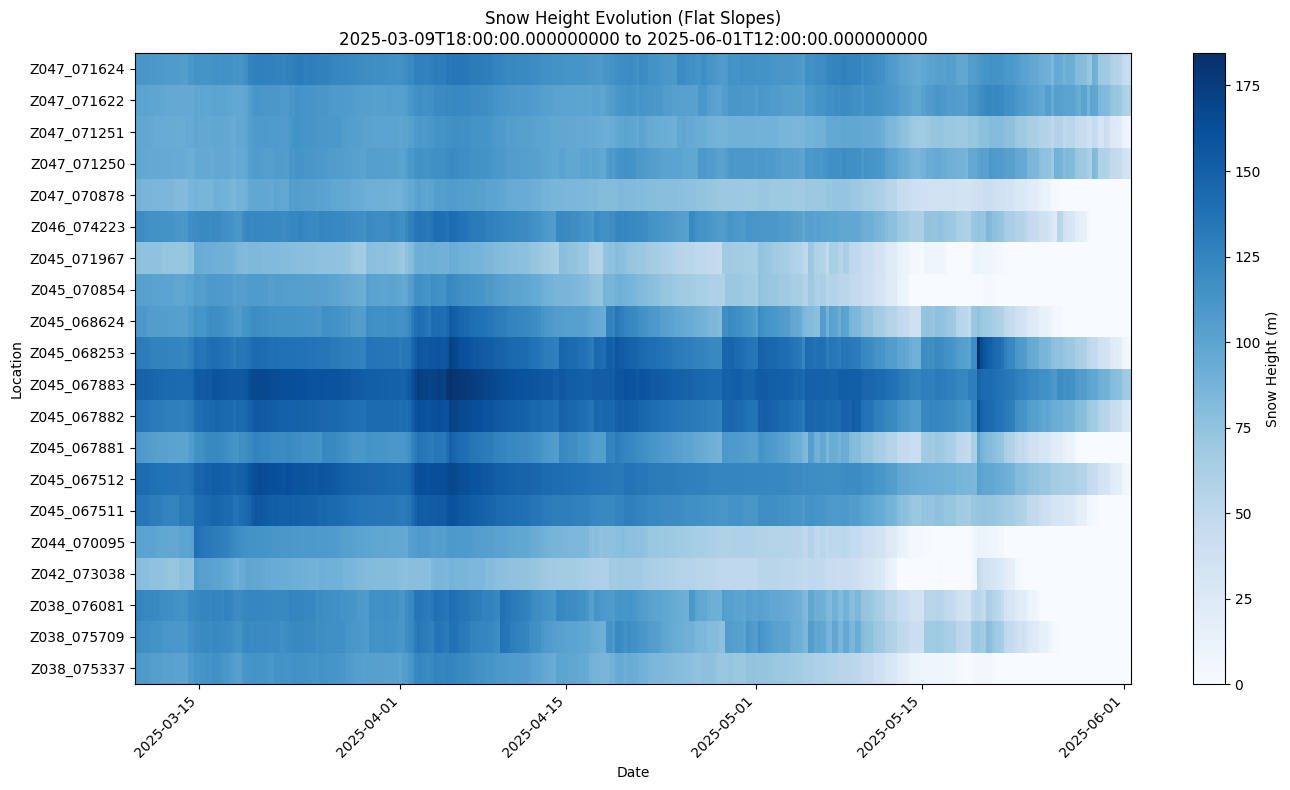


💡 Showing first 20 of 69 locations
   (Large datasets are limited for visualization)


In [ ]:
if 'HS' in ds.data:
    # Dynamically select last 2 weeks of available data
    time_values = ds.data.time.values
    
    # Get last 14 days (or all data if less than 14 days)
    n_times = len(time_values)
    n_days_to_plot = min(14 * 24, n_times)  # 14 days * 24 hours, or all available
    
    print(f"Creating heatmap for last {n_days_to_plot} timesteps...\n")
    
    # Select recent data
    recent = ds.isel(time=slice(-n_days_to_plot, None))
    hs_heatmap = recent.data['HS'].isel(slope=0, realization=0).compute()
    
    # Limit to first 20 locations if dataset is very large
    n_locs_to_plot = min(20, len(hs_heatmap.location))
    hs_heatmap = hs_heatmap.isel(location=slice(0, n_locs_to_plot))
    
    if hs_heatmap.sizes['time'] == 0:
        print("⚠️  No data available for heatmap")
    else:
        fig, ax = plt.subplots(figsize=(14, 8))
        
        # Create heatmap
        mesh = ax.pcolormesh(
            hs_heatmap.time.values,
            range(len(hs_heatmap.location)),
            hs_heatmap.values,
            cmap='Blues',
            shading='nearest'
        )
        
        ax.set_yticks(range(len(hs_heatmap.location)))
        ax.set_yticklabels(hs_heatmap.location.values)
        ax.set_xlabel('Date')
        ax.set_ylabel('Location')
        
        time_start = hs_heatmap.time.values[0]
        time_end = hs_heatmap.time.values[-1]
        ax.set_title(f'Snow Height Evolution (Flat Slopes)\n{time_start} to {time_end}')
        
        cbar = plt.colorbar(mesh, ax=ax, label='Snow Height (cm)')
        plt.xticks(rotation=45, ha='right')
        plt.tight_layout()
        plt.show()
        
        if n_locs_to_plot < len(recent.data.location):
            print(f"\n💡 Showing first {n_locs_to_plot} of {len(recent.data.location)} locations")
            print(f"   (Large datasets are limited for visualization)")

## 9. Best Practices Summary

### ✅ DO:

1. **Select before computing**: Reduce data size first
   ```python
   result = ds.sel(location='VIR1A').data['temp'].mean(dim='layer').compute()
   ```

2. **Compute at logical breakpoints**: Reset complex task graphs
   ```python
   daily = ds.data['temp'].resample(time='1D').mean().compute()
   analysis = daily.mean(dim='location')  # Continue with smaller data
   ```

3. **Use aggregations on lazy arrays**: Let Dask optimize
   ```python
   mean_temp = ds.data['temperature'].mean(dim=['time', 'slope']).compute()
   ```

4. **Explore metadata freely**: Coordinates, dimensions, attributes are fast
   ```python
   print(ds.data.coords)
   print(ds.data.sizes)
   ```

### ❌ DON'T:

1. **Don't compute entire datasets**:
   ```python
   all_data = ds.data.compute()  # ❌ BAD - loads everything!
   ```

2. **Don't compute in loops** without good reason:
   ```python
   for loc in locations:
       result = ds.sel(location=loc).compute()  # ❌ Inefficient
   ```

3. **Don't chain too many operations** without computing:
   ```python
   # 20 chained operations → huge task graph
   result = data.op1().op2()...op20()  # ❌ Compute midway!
   ```

4. **Don't ignore chunk sizes**: Check and optimize if needed
   ```python
   print(ds.data['temperature'].chunks)  # Monitor chunks
   ```

---

## 10. When to Compute? Decision Tree

```
Are you doing exploratory analysis?
│
├─ Yes → Keep lazy as long as possible
│        Only compute for plots/summaries
│
└─ No → Are you selecting a small subset?
         │
         ├─ Yes → Select, then compute
         │
         └─ No → Are you aggregating/reducing dimensions?
                 │
                 ├─ Yes → Aggregate, then compute result
                 │
                 └─ No → Have you chained 10+ operations?
                         │
                         ├─ Yes → Compute to reset task graph
                         │
                         └─ No → Stay lazy, continue building
```

---

## Key Takeaway

**Think of lazy evaluation like meal planning:**
- 📝 Build your recipe (define operations)
- 🔪 Prep ingredients (select/subset data)
- 🍳 Cook only what you need (compute efficiently)
- ♻️  Clean up between courses (strategic compute to reset)

This workflow lets you work with massive datasets on modest hardware! 🚀

## Bonus: Monitoring Dask Performance

In [20]:
# Check memory usage and task graph complexity
def analyze_lazy_array(arr, name="array"):
    """Helper to inspect a lazy array."""
    print(f"\n{'='*50}")
    print(f"Analysis: {name}")
    print(f"{'='*50}")
    print(f"Shape: {arr.shape}")
    print(f"Dtype: {arr.dtype}")
    print(f"Type: {type(arr.data)}")
    
    if hasattr(arr, 'chunks'):
        print(f"Chunks: {arr.chunks}")
        print(f"Number of chunks: {len(arr.chunks[0]) if arr.chunks else 0}")
    
    if hasattr(arr, '__dask_graph__'):
        graph_size = len(arr.__dask_graph__())
        print(f"Task graph size: {graph_size} tasks")
        
        if graph_size > 1000:
            print("⚠️  WARNING: Large task graph! Consider computing intermediate results.")
        elif graph_size > 5000:
            print("🚨 ALERT: Very large task graph! This will be slow.")
        else:
            print("✅ Task graph looks reasonable")
    
    # Estimate memory if computed
    nbytes = arr.nbytes
    mb = nbytes / 1024**2
    gb = nbytes / 1024**3
    
    if gb > 1:
        print(f"Estimated memory: {gb:.2f} GB")
    else:
        print(f"Estimated memory: {mb:.2f} MB")

# Example usage
analyze_lazy_array(ds.data['temperature'], "Temperature")


Analysis: Temperature
Shape: (69, 909, 4, 1, 119)
Dtype: float32
Type: <class 'dask.array.core.Array'>
Chunks: ((1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1), (100, 100, 100, 100, 100, 100, 100, 100, 100, 9), (1, 1, 1, 1), (1,), (119,))
Number of chunks: 69
Task graph size: 31626 tasks
⚠️  WARNING: Large task graph! Consider computing intermediate results.
Estimated memory: 113.89 MB
